# Additional models evaluated on the main project's A/B protocol

**D-071: exploratory, validation only.** This notebook trains random forest, Extra Trees and histogram gradient boosting, and reruns the original logistic/LightGBM controls through the **existing main-project evaluation runner**, with its constant/random floors.

This is the main task: one forecast per turbine-day, seven-day feature history, a 30-day positive horizon, a 31–60-day exclusion zone, and the existing A/B labels. **A** means episodes of daily time-error; **B** means SCADA-derived stop episodes. It is not the Iteration2 icing-code task. Existing labels and feature files are reused, including their eligibility, coverage and purging decisions.

Train years: 2016, 2017, 2018 and 2020. Validation: 2021 and 2022. Settings are read from `configs/protocol.yaml`; no negative subsampling is applied. Preprocessing is fitted only on labelled training rows. Main metrics are AP with turbine-bootstrap intervals, event recall at the configured false-alarm budget, median lead days, and realised false-alert-day rate. Supplemental precision and confusion matrices refer to labelled turbine-days, not independent events.

**No test scoring is implemented here.** The main test years were previously inspected (D-061); fresh experimentation on them could only be a post-hoc comparison, not independent confirmation. Original frozen selections, registry membership and report files are preserved. Fixed exploratory tree parameters are logged in D-071 before these runs. This notebook calls the runner directly rather than importing the registry, which currently contains pre-existing merge markers.

Prerequisite files: `data/interim/features/daily_features.parquet`, `data/interim/labels/{a,b}_labels.parquet`, and `{a,b}_episodes.parquet`. Do not rebuild labels with different rules if the objective is comparison with the main task. Actual available rows may differ from the historical report; the freshly rerun controls are the same-row comparators.


In [2]:
from pathlib import Path
import sys, json, hashlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from IPython.display import display
import joblib

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'configs' / 'protocol.yaml').is_file() and (p / 'src' / 'wt_predmaint').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the main ENGG2112-T3-G7 project, not Iteration2.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from wt_predmaint.config import load_protocol
from wt_predmaint.models.base import attach_labels, labelled
from wt_predmaint.models.additional import build_additional_comparison
from wt_predmaint.evaluation.runner import run_baselines
from wt_predmaint.evaluation.metrics import evaluate, episodes_in_split
from wt_predmaint.evaluation.plotting import calendar_frame, plot_risk_timeline

cfg = load_protocol()
TARGETS = ['a', 'b']
INTERIM = ROOT / 'data' / 'interim'
# Leave None for the protocol's 1,000 turbine bootstrap resamples.
BOOTSTRAP_RESAMPLES = None
PLOT_TURBINE = 2304511
RUN_TRAINING = True  # False reloads this exact experiment's saved validation metrics/scores.
assert set(TARGETS) <= {'a', 'b'} and TARGETS
validation_years = cfg['splits']['val_years']
train_years = cfg['splits']['train_years']
test_years = cfg['splits']['test_years']
assert set(train_years).isdisjoint(validation_years)
assert (set(train_years) | set(validation_years)).isdisjoint(test_years)
display(pd.DataFrame({'Split': ['Train', 'Validation', 'Reserved test (not loaded)'],
                      'Years': [train_years, validation_years, test_years]}))
print('New classifier settings:')
print(json.dumps(cfg['additional_validation_models'], indent=2))


                        Split                     Years
0                       Train  [2016, 2017, 2018, 2020]
1                  Validation              [2021, 2022]
2  Reserved test (not loaded)  [2023, 2024, 2025, 2026]
New classifier settings:
{
  "output_dir": "reports/additional_models_main_protocol",
  "include_frozen_controls": true,
  "nonfinite_score_fallback": 0.5,
  "n_jobs": 4,
  "random_forest": {
    "n_estimators": 150,
    "max_depth": 10,
    "min_samples_leaf": 20,
    "max_features": "sqrt",
    "class_weight": "balanced_subsample"
  },
  "extra_trees": {
    "n_estimators": 150,
    "max_depth": 12,
    "min_samples_leaf": 10,
    "max_features": "sqrt",
    "class_weight": "balanced"
  },
  "histogram_gradient_boosting": {
    "max_iter": 150,
    "max_leaf_nodes": 15,
    "learning_rate": 0.05,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0,
    "early_stopping": false
  }
}


In [3]:
# Read only the main development years; do not materialise test-year rows.
development_years = sorted(set(train_years) | set(validation_years))
first_day = pd.Timestamp(min(development_years), 1, 1)
last_day = pd.Timestamp(max(development_years) + 1, 1, 1)
feature_path = INTERIM / 'features' / 'daily_features.parquet'
needed = [feature_path] + [INTERIM / 'labels' / f'{target}_{suffix}.parquet'
                          for target in TARGETS for suffix in ['labels', 'episodes']]
missing = [str(path) for path in needed if not path.is_file()]
if missing:
    raise FileNotFoundError('Prepare the main project feature/label files first: ' + ', '.join(missing))
features = pd.read_parquet(feature_path, filters=[('Day', '>=', first_day), ('Day', '<', last_day)])
features = features.loc[features.Day.dt.year.isin(development_years)].copy()
assert not features.Day.dt.year.isin(test_years).any()
if features.duplicated(['StationId', 'Day']).any():
    raise ValueError('Duplicate turbine-days in the main feature table.')
labels, episodes, tables, coverage = {}, {}, {}, []
for target in TARGETS:
    path = INTERIM / 'labels' / f'{target}_labels.parquet'
    lab = pd.read_parquet(path, filters=[('Day', '>=', first_day), ('Day', '<', last_day)])
    lab = lab.loc[lab.Day.dt.year.isin(development_years)].copy()
    if lab.duplicated(['StationId', 'Day']).any():
        raise ValueError(f'Duplicate turbine-day labels for {target}')
    ep = pd.read_parquet(INTERIM / 'labels' / f'{target}_episodes.parquet',
                         filters=[('Start', '<', last_day)])
    joined = attach_labels(features, lab, cfg)
    assert not joined.split.eq('test').any()
    for split in ['train', 'val']:
        used = labelled(joined, split)
        if used.empty or used.label.nunique() < 2:
            raise ValueError(f'{target}/{split}: both classes are required; check source coverage.')
        coverage.append({'target': target.upper(), 'split': split, 'rows': len(used),
                         'positive_rows': int(used.label.sum()), 'prevalence': used.label.mean(),
                         'turbines': used.StationId.nunique(), 'first_day': used.Day.min(), 'last_day': used.Day.max()})
    labels[target], episodes[target], tables[target] = lab, ep, joined
coverage = pd.DataFrame(coverage)
display(coverage)
print('These are current cached input counts, not assumed historical report counts.')

provenance = {'protocol': cfg, 'targets': TARGETS, 'bootstrap_override': BOOTSTRAP_RESAMPLES,
              'inputs': [{'path': str(path.resolve()), 'size': path.stat().st_size,
                          'mtime_ns': path.stat().st_mtime_ns} for path in needed],
              'model_implementation_sha256': hashlib.sha256(
                  (ROOT / 'src' / 'wt_predmaint' / 'models' / 'additional.py').read_bytes()).hexdigest(),
              'evaluation_scope': 'validation only; no test scoring'}
RUN_ID = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()[:12]
OUTPUT = ROOT / cfg['additional_validation_models']['output_dir'] / RUN_ID
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / 'configuration.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
coverage.to_csv(OUTPUT / 'coverage.csv', index=False)
print('Isolated output folder:', OUTPUT)


These are current cached input counts, not assumed historical report counts.
Isolated output folder: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\reports\additional_models_main_protocol\fd99c521d412


,target,split,rows,positive_rows,prevalence,turbines,first_day,last_day
0,A,train,22309,8315,0.372720,21,2016-01-01,2020-11-01
1,A,val,9690,4558,0.470382,21,2021-01-01,2022-11-01
2,B,train,21199,10171,0.479787,21,2016-01-01,2020-11-01
3,B,val,8827,4346,0.492353,21,2021-01-01,2022-11-01


In [4]:
# The shared runner fits models, checks their score contract, calibrates the main
# false-alert-day threshold on validation, and computes the original bootstrap metrics.
all_results, score_frames, supplemental, per_turbine_rows = [], {}, [], []
for target in TARGETS:
    print(f'Target {target.upper()}: training and evaluating main-protocol classifiers...', flush=True)
    table = tables[target]
    if RUN_TRAINING:
        candidates = build_additional_comparison(target, cfg)
        result = run_baselines(candidates, table, episodes[target], cfg, target,
                               splits=('val',), frozen=False, resamples=BOOTSTRAP_RESAMPLES)
        result.table.to_csv(OUTPUT / f'{target}_validation_metrics.csv', index=False)
        joblib.dump({model.name: model for model in candidates}, OUTPUT / f'{target}_models.joblib')
        for (variant, name, split), values in result.scores.items():
            assert split == 'val'
            values.to_parquet(OUTPUT / f'{target}_{name}_validation_scores.parquet', index=False)
        target_result = result.table
    else:
        target_result = pd.read_csv(OUTPUT / f'{target}_validation_metrics.csv')
    all_results.append(target_result)
    eps = episodes_in_split(episodes[target], validation_years)
    base = labelled(table, 'val')[['StationId', 'Day', 'label']]
    for row in target_result.itertuples(index=False):
        name = row.model
        values = pd.read_parquet(OUTPUT / f'{target}_{name}_validation_scores.parquet')
        frame = base.merge(values, on=['StationId', 'Day'], validate='one_to_one')
        assert len(frame) == len(base)
        score_frames[(target, name)] = frame
        prediction = frame.score.to_numpy() > row.threshold  # MAIN strict rule, not >=.
        truth = frame.label.to_numpy(dtype=int)
        tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
        supplemental.append({'target': target.upper(), 'model': name, 'split': 'val',
            'window_precision': precision_score(truth, prediction, zero_division=0),
            'window_recall': recall_score(truth, prediction, zero_division=0),
            'window_F1': f1_score(truth, prediction, zero_division=0),
            'ROC_AUC': roc_auc_score(truth, frame.score), 'TP': int(tp), 'FP': int(fp),
            'FN': int(fn), 'TN': int(tn), 'threshold': row.threshold})
        for station, group in frame.groupby('StationId'):
            per_turbine_rows.append({'target': target.upper(), 'model': name, 'StationId': station,
                **evaluate(group, eps.loc[eps.StationId.eq(station)], row.threshold, cfg)})
        print(f'{target.upper()} / {name}: AP={row.pr_auc:.4f}, event recall={row.recall:.3f}, false-alert rate={row.false_alarms_per_turbine_month:.3f}', flush=True)
results = pd.concat(all_results, ignore_index=True)
supplemental = pd.DataFrame(supplemental)
per_turbine = pd.DataFrame(per_turbine_rows)
results.to_csv(OUTPUT / 'validation_metrics.csv', index=False)
supplemental.to_csv(OUTPUT / 'validation_window_metrics.csv', index=False)
per_turbine.to_csv(OUTPUT / 'validation_per_turbine.csv', index=False)
print('Validation complete. No test predictions were requested or produced.')


Target A: training and evaluating main-protocol classifiers...
C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
A / B0a_constant: AP=0.4704, event recall=0.000, false-alert rate=0.000
A / B0b_random: AP=0.4649, event recall=0.780, false-alert rate=0.999
A / B4_logistic: AP=0.4466, event recall=0.234, false-alert rate=0.999
A / L1_lgbm: AP=0.4495, event recall=0.139, false-alert rate=0.999
A / X_RF: AP=0.4105, event recall=0.206, false-alert rate=0.999
A / X_ExtraTrees: AP=0.4141, event recall=0.258, false-alert rate=0.999

In [5]:
display(results[['target', 'model', 'prevalence', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi',
                 'random_floor_pr_auc', 'recall', 'recall_lo', 'recall_hi', 'random_floor_recall',
                 'median_lead_days', 'false_alarms_per_turbine_month', 'n_episodes', 'n_detected']].round(5))
display(supplemental.round(5))
print('Main recall is EVENT recall; window_recall counts labelled turbine-days.')
print('Thresholds use validation false-alarm budget, never maximum F1.')
print('Intervals bootstrap turbines with the threshold fixed; they do not include model-selection uncertainty.')
print('Precision/confusion matrices are supplemental day-level diagnostics, not replacements for main event metrics.')


Main recall is EVENT recall; window_recall counts labelled turbine-days.
Thresholds use validation false-alarm budget, never maximum F1.
Intervals bootstrap turbines with the threshold fixed; they do not include model-selection uncertainty.
Precision/confusion matrices are supplemental day-level diagnostics, not replacements for main event metrics.


,target,model,prevalence,pr_auc,pr_auc_lo,pr_auc_hi,random_floor_pr_auc,recall,recall_lo,recall_hi,random_floor_recall,median_lead_days,false_alarms_per_turbine_month,n_episodes,n_detected
0,A,B0a_constant,0.47038,0.47038,0.41084,0.53780,0.46493,0.00000,0.00000,0.00000,0.77990,NaN,0.00000,209,0
1,A,B0b_random,0.47038,0.46493,0.40446,0.53476,0.46493,0.77990,0.72222,0.84238,0.77990,20.0,0.99888,209,163
2,A,B4_logistic,0.47038,0.44657,0.37686,0.55234,0.46493,0.23445,0.16752,0.31473,0.77990,18.0,0.99888,209,49
3,A,L1_lgbm,0.47038,0.44949,0.39181,0.53999,0.46493,0.13876,0.08070,0.20709,0.77990,27.0,0.99888,209,29
4,A,X_RF,0.47038,0.41046,0.34272,0.50651,0.46493,0.20574,0.14216,0.27277,0.77990,20.0,0.99888,209,43
5,A,X_ExtraTrees,0.47038,0.41410,0.34697,0.50688,0.46493,0.25837,0.19903,0.31629,0.77990,19.0,0.99888,209,54
6,A,X_HistGB,0.47038,0.42877,0.37026,0.51880,0.46493,0.11962,0.06603,0.18434,0.77990,29.0,0.99888,209,25
7,B,B0a_constant,0.49235,0.49235,0.42932,0.56247,0.48300,0.00000,0.00000,0.00000,0.76042,NaN,0.00000,192,0
8,B,B0b_random,0.49235,0.48300,0.41876,0.55748,0.48300,0.76042,0.70301,0.81523,0.76042,21.0,0.99999,192,146
9,B,B4_logistic,0.49235,0.44947,0.37166,0.53246,0.48300,0.24479,0.16393,0.33338,0.76042,21.0,0.99999,192,47


,target,model,split,window_precision,window_recall,window_F1,ROC_AUC,TP,FP,FN,TN,threshold
0,A,B0a_constant,val,0.00000,0.00000,0.00000,0.50000,0,0,4558,5132,0.00000
1,A,B0b_random,val,0.45172,0.05748,0.10199,0.49708,262,318,4296,4814,0.94262
2,A,B4_logistic,val,0.37647,0.04212,0.07577,0.46635,192,318,4366,4814,0.81614
3,A,L1_lgbm,val,0.42391,0.05134,0.09159,0.46606,234,318,4324,4814,0.76330
4,A,X_RF,val,0.31906,0.03269,0.05930,0.42069,149,318,4409,4814,0.61764
5,A,X_ExtraTrees,val,0.31613,0.03225,0.05853,0.42239,147,318,4411,4814,0.59839
6,A,X_HistGB,val,0.42287,0.05112,0.09121,0.43460,233,318,4325,4814,0.75651
7,B,B0a_constant,val,0.00000,0.00000,0.00000,0.50000,0,0,4346,4481,0.00000
8,B,B0b_random,val,0.47464,0.06029,0.10698,0.48812,262,290,4084,4191,0.93958
9,B,B4_logistic,val,0.44231,0.05292,0.09453,0.43396,230,290,4116,4191,0.82546


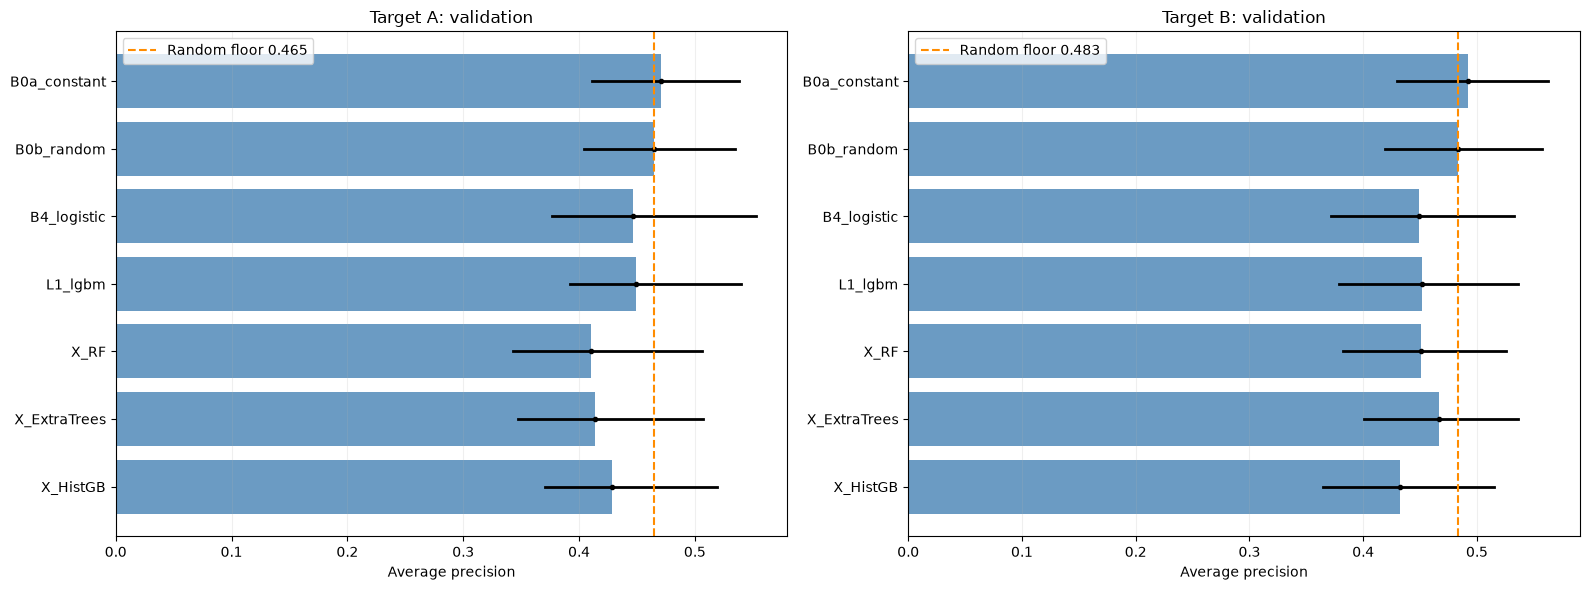

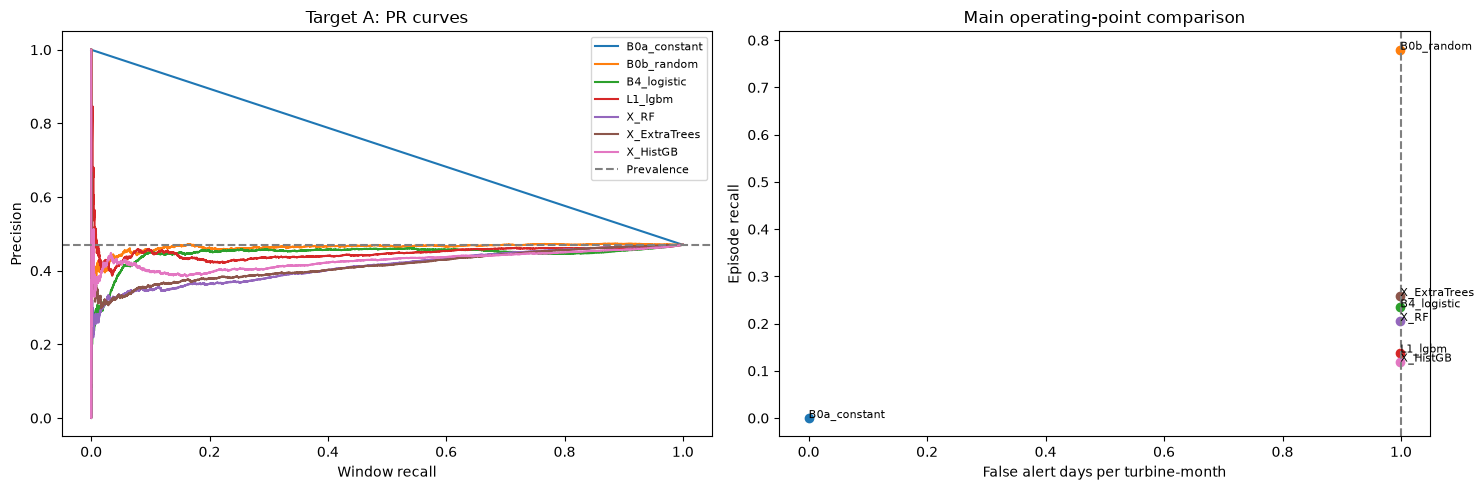

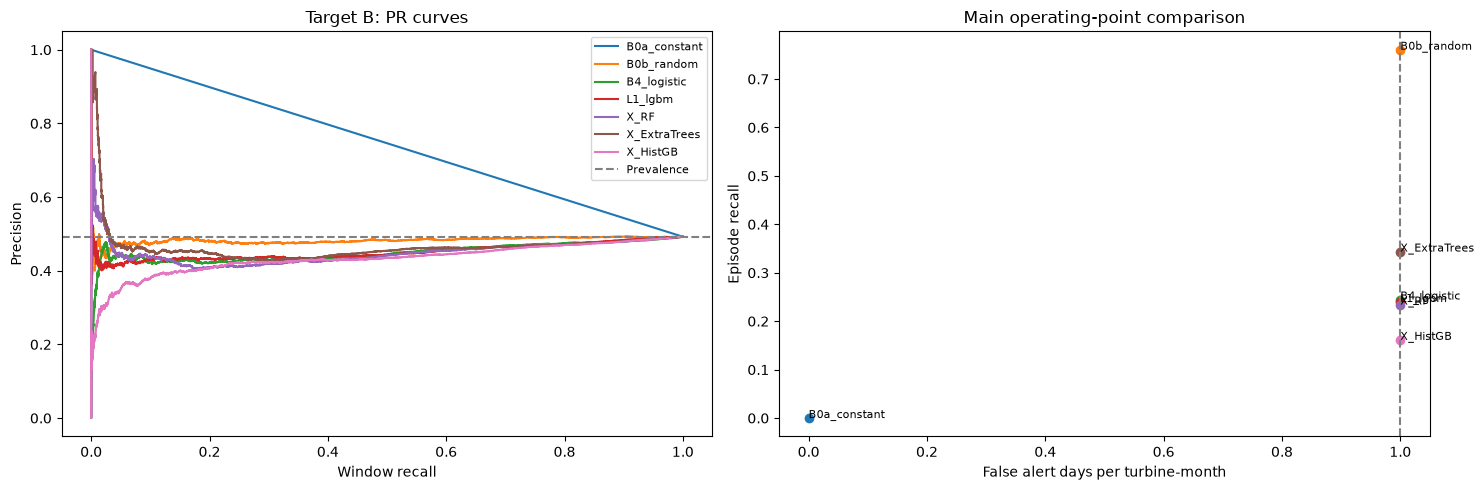

In [6]:
# Main-task AP with 95% turbine-bootstrap intervals and the paired random baseline.
fig, axes = plt.subplots(1, len(TARGETS), figsize=(8 * len(TARGETS), 6), squeeze=False)
for ax, target in zip(axes[0], TARGETS):
    rows = results.loc[results.target.eq(target.upper())].reset_index(drop=True)
    y = np.arange(len(rows))
    ax.barh(y, rows.pr_auc, color='steelblue', alpha=.8)
    for i, row in enumerate(rows.itertuples(index=False)):
        ax.plot([row.pr_auc_lo, row.pr_auc_hi], [i, i], color='black', linewidth=2)
        ax.plot(row.pr_auc, i, 'ko', markersize=3)
    floor = rows.random_floor_pr_auc.iloc[0]
    ax.axvline(floor, color='darkorange', linestyle='--', label=f'Random floor {floor:.3f}')
    ax.set(yticks=y, yticklabels=rows.model, xlabel='Average precision', title=f'Target {target.upper()}: validation')
    ax.invert_yaxis(); ax.legend(); ax.grid(axis='x', alpha=.2)
fig.tight_layout(); fig.savefig(OUTPUT / 'validation_AP_intervals.png', dpi=150); plt.show()

for target in TARGETS:
    rows = results.loc[results.target.eq(target.upper())]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for row in rows.itertuples(index=False):
        frame = score_frames[(target, row.model)]
        precision, recall, _ = precision_recall_curve(frame.label, frame.score)
        axes[0].plot(recall, precision, label=row.model)
        axes[1].scatter(row.false_alarms_per_turbine_month, row.recall)
        axes[1].annotate(row.model, (row.false_alarms_per_turbine_month, row.recall), fontsize=8)
    axes[0].axhline(rows.prevalence.iloc[0], color='grey', linestyle='--', label='Prevalence')
    axes[0].set(xlabel='Window recall', ylabel='Precision', title=f'Target {target.upper()}: PR curves')
    axes[0].legend(fontsize=8)
    axes[1].axvline(cfg['evaluation']['false_alarm_budget_per_turbine_month'], linestyle='--', color='grey')
    axes[1].set(xlabel='False alert days per turbine-month', ylabel='Episode recall', title='Main operating-point comparison')
    fig.tight_layout(); fig.savefig(OUTPUT / f'{target}_PR_and_event_recall.png', dpi=150); plt.show()


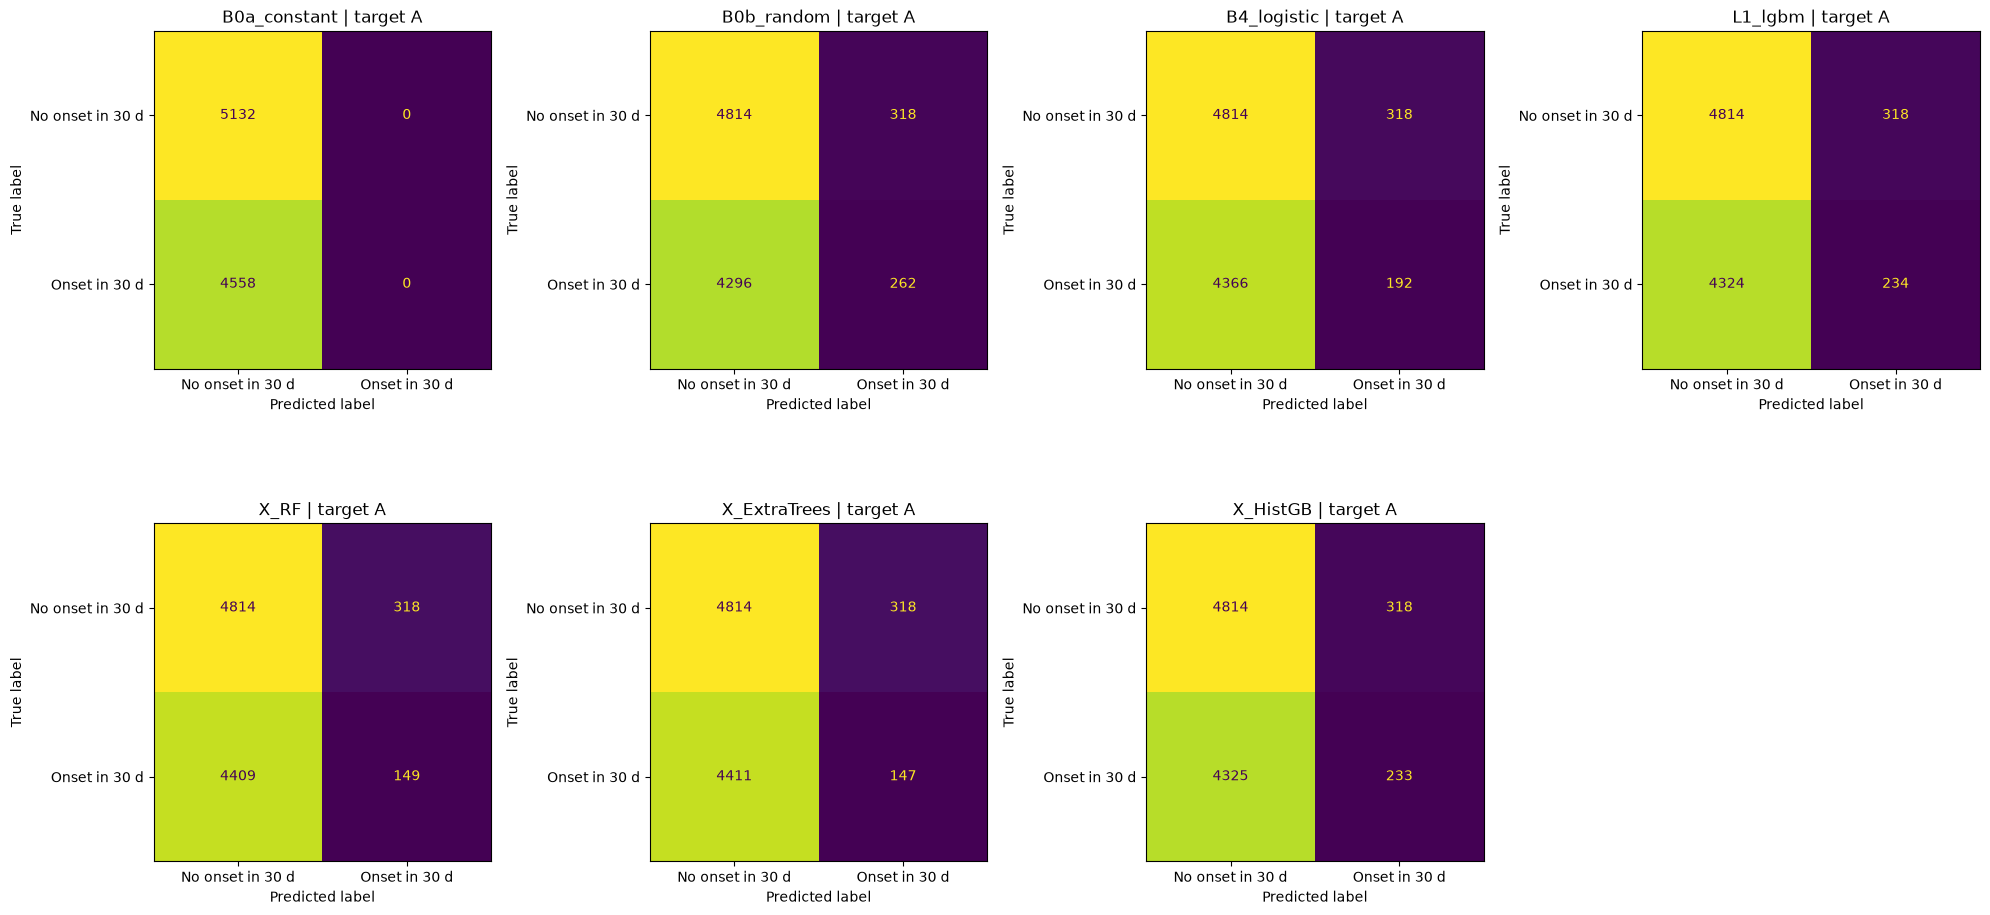

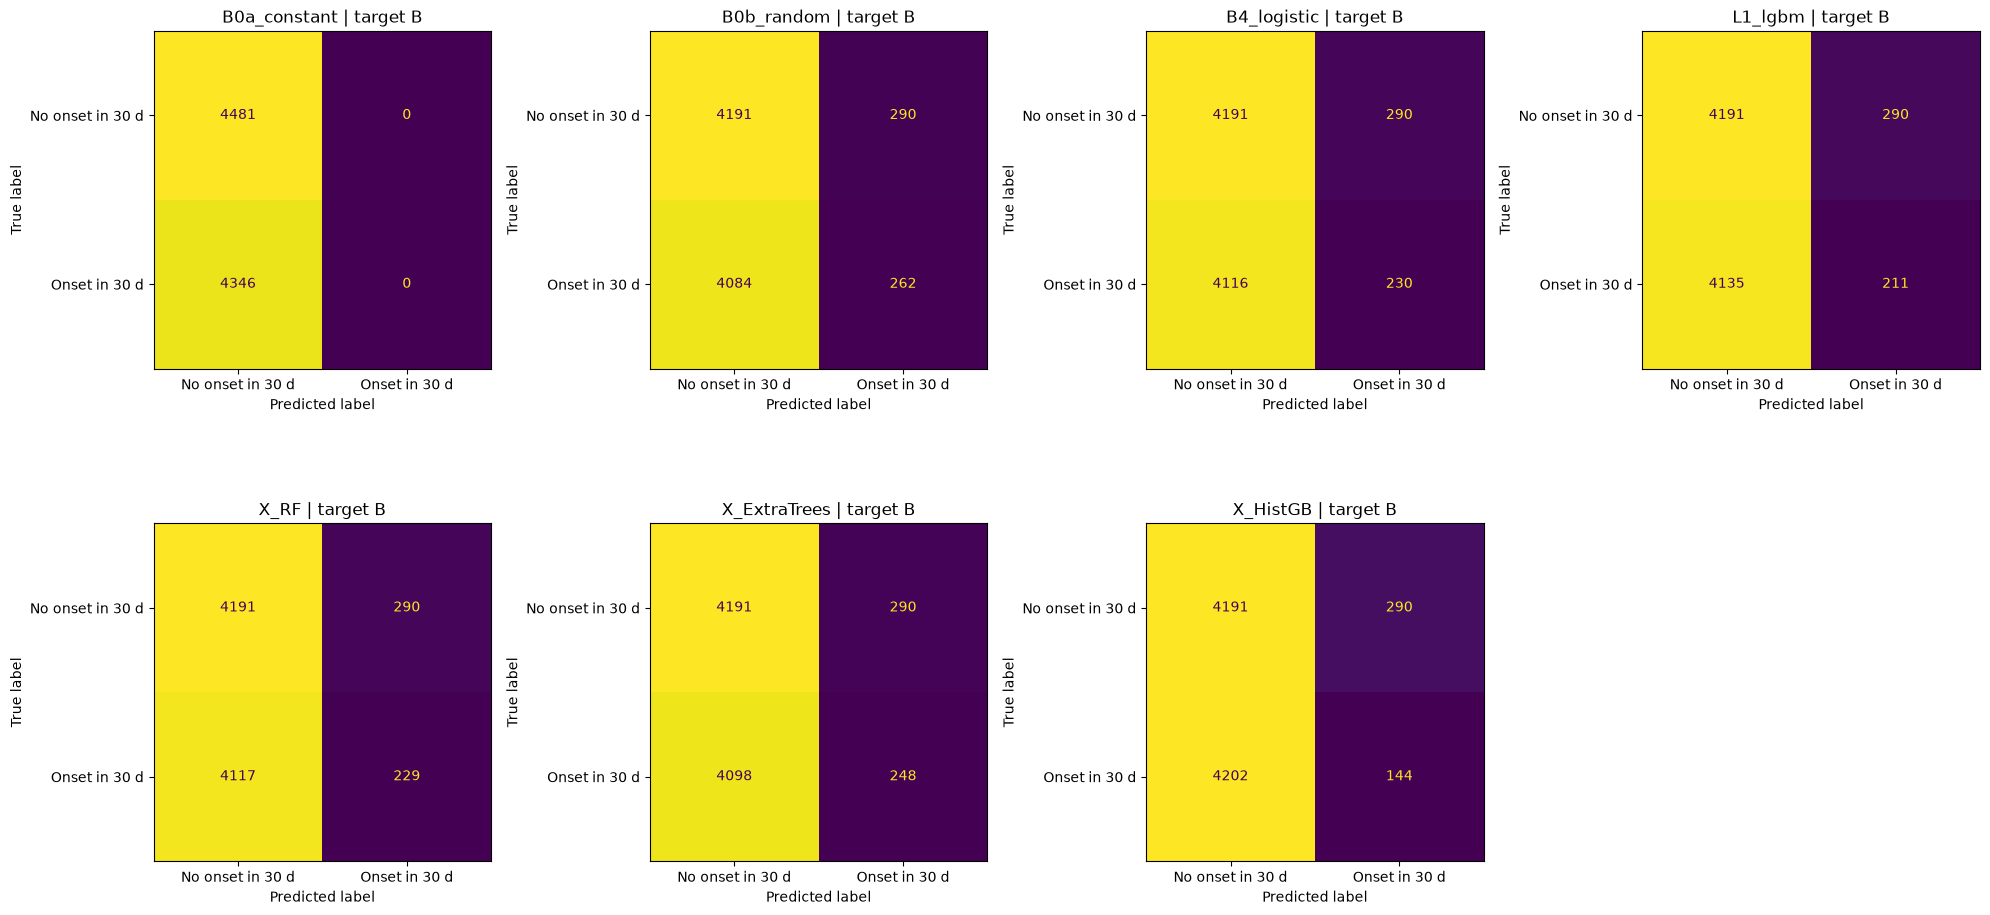

In [7]:
# Day-level confusion matrices at the shared evaluator's validation thresholds.
for target in TARGETS:
    rows = results.loc[results.target.eq(target.upper())]
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    for ax, row in zip(axes.flat, rows.itertuples(index=False)):
        frame = score_frames[(target, row.model)]
        ConfusionMatrixDisplay.from_predictions(frame.label.astype(int), frame.score.gt(row.threshold),
            labels=[0, 1], display_labels=['No onset in 30 d', 'Onset in 30 d'],
            ax=ax, colorbar=False, values_format='d')
        ax.set_title(f'{row.model} | target {target.upper()}')
    for ax in axes.flat[len(rows):]:
        ax.axis('off')
    fig.tight_layout(); fig.savefig(OUTPUT / f'{target}_confusion_matrices.png', dpi=150); plt.show()


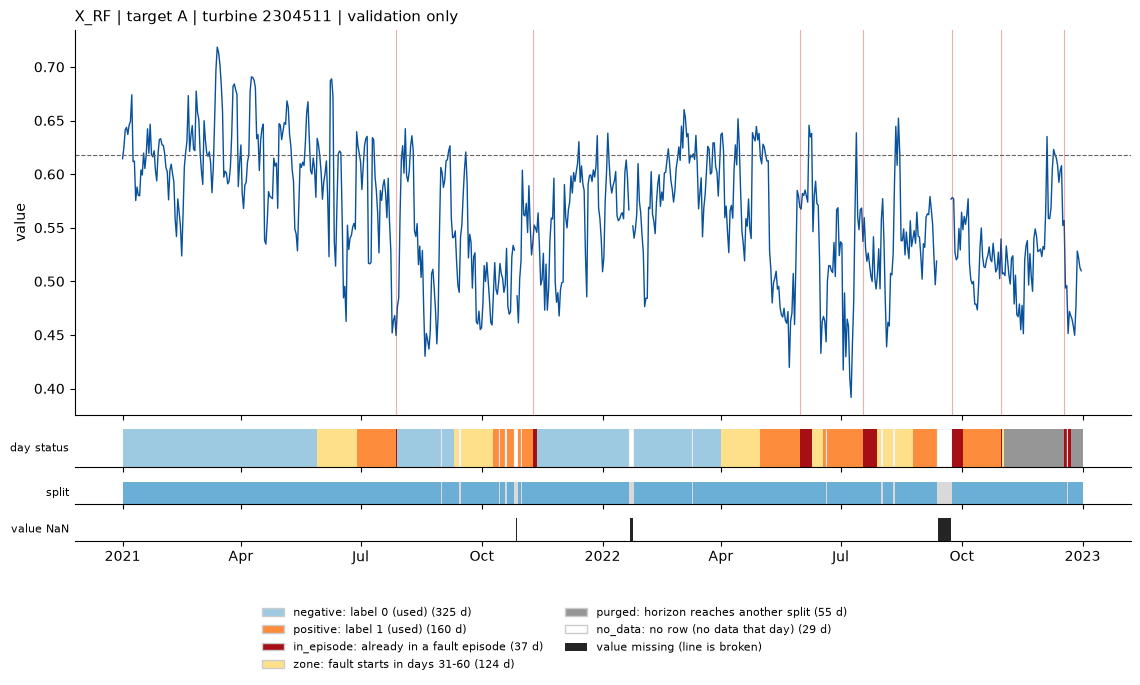

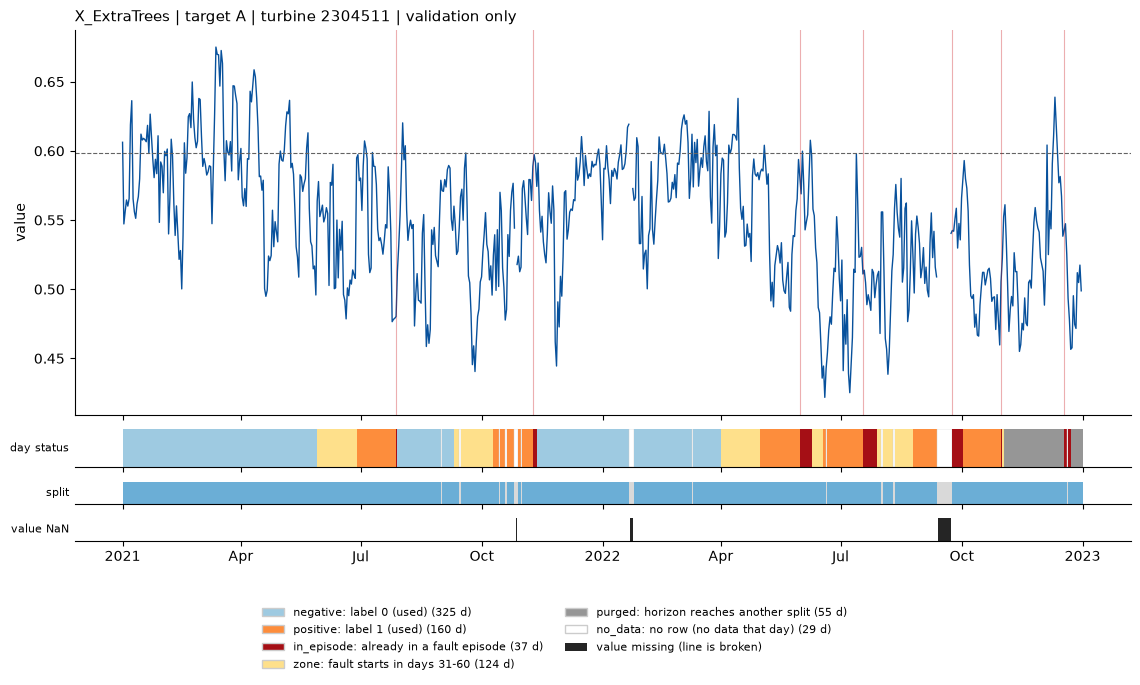

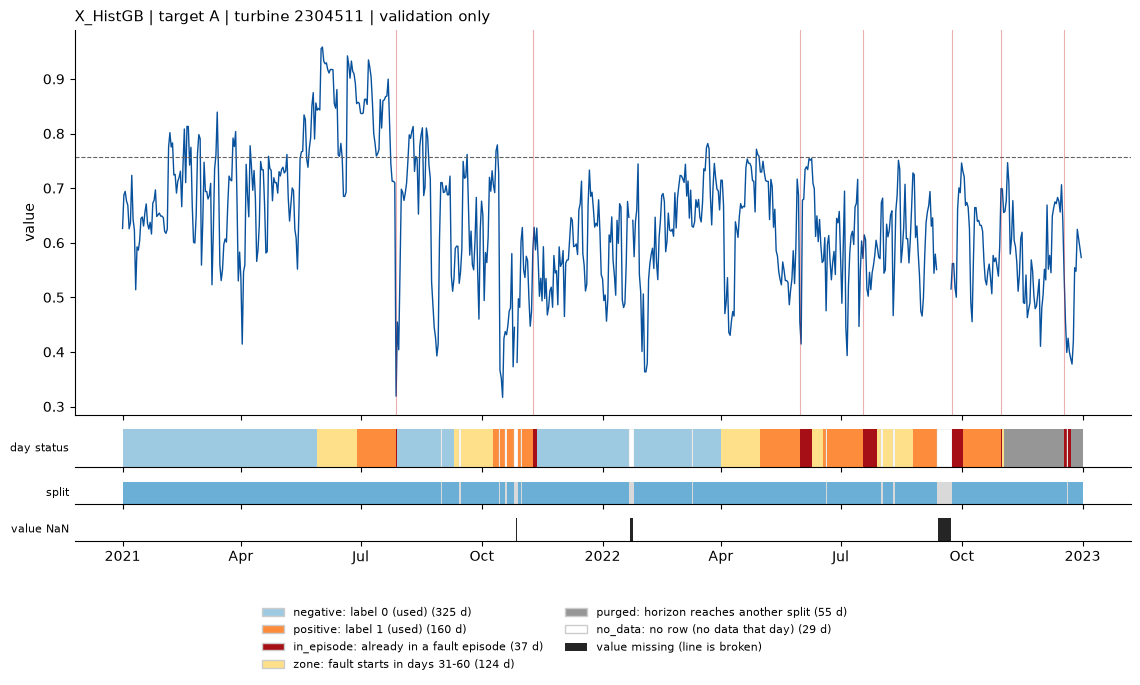

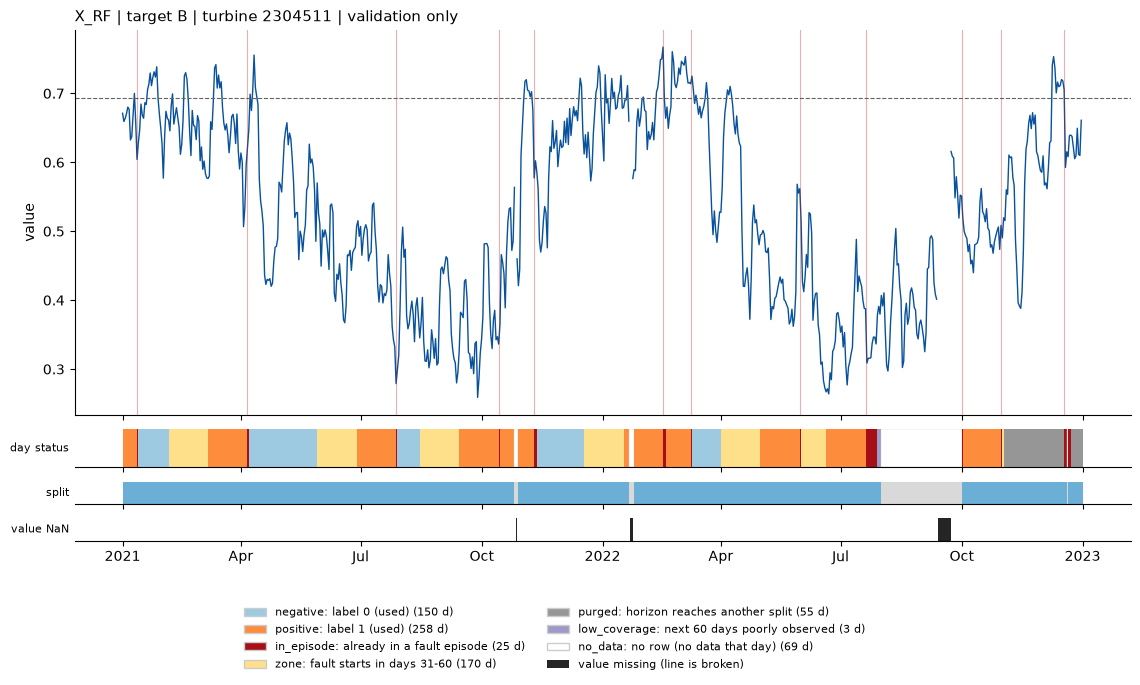

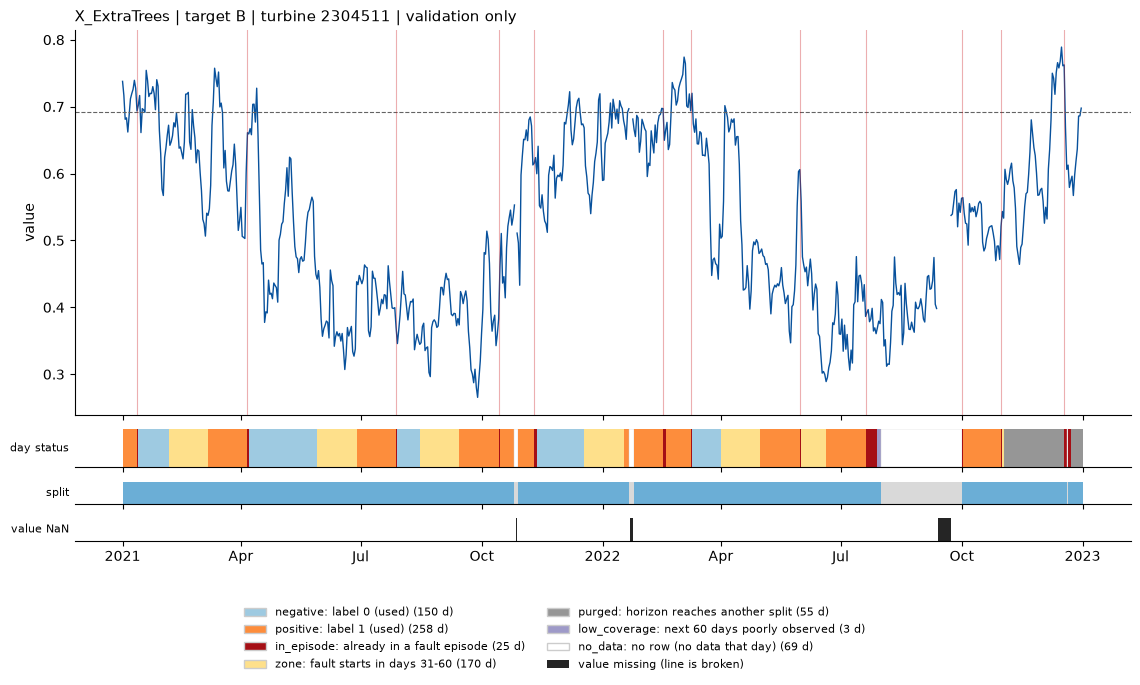

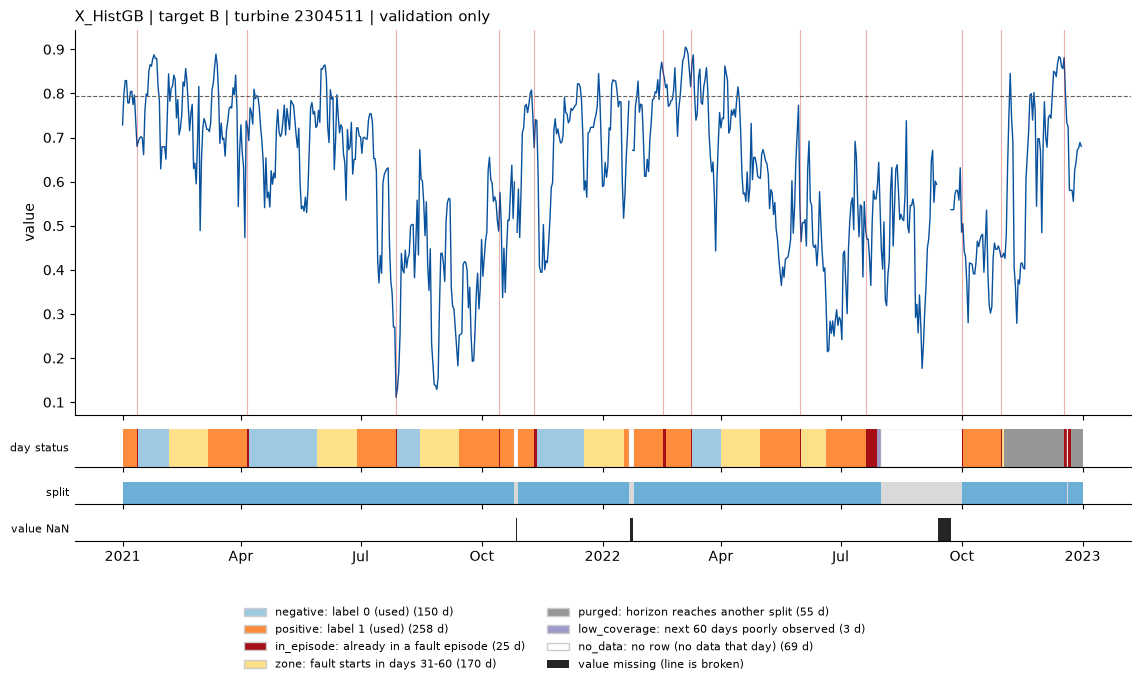

In [8]:
# Main-project timeline utility preserves status bands and explains gaps.
for target in TARGETS:
    rows = results.loc[results.target.eq(target.upper()) & results.model.str.startswith('X_')]
    for row in rows.itertuples(index=False):
        values = pd.read_parquet(OUTPUT / f'{target}_{row.model}_validation_scores.parquet')
        if not values.StationId.eq(PLOT_TURBINE).any():
            print('No plotted turbine', PLOT_TURBINE, 'for', target); continue
        calendar = calendar_frame(values, labels[target], PLOT_TURBINE, 'score',
                                  start=f'{min(validation_years)}-01-01', end=f'{max(validation_years)}-12-31')
        fig = plot_risk_timeline(calendar, episodes[target], station=PLOT_TURBINE,
                                 threshold=row.threshold,
                                 title=f'{row.model} | target {target.upper()} | turbine {PLOT_TURBINE} | validation only')
        fig.savefig(OUTPUT / f'{target}_{row.model}_timeline_{PLOT_TURBINE}.png', dpi=150)
        plt.show()


## What can be concluded

These runs are an exploratory comparison on repeatedly used validation years. Read confidence intervals and the paired random-score floor before claiming an improvement. A higher point estimate or attractive timeline alone is not evidence of independent predictive ability. The default parameters were declared before this run, but choosing among them afterwards is still development selection.

Current cached rows can differ from the historical report. Compare the newly evaluated models against the freshly fitted controls on these identical rows; do not silently substitute published values from different coverage. Original LightGBM keeps its native missing-value handling, whereas the new tree models use train-only median imputation: this compares complete model pipelines, not algorithms isolated from all preprocessing differences.

All outputs go to the isolated experiment folder printed above. `validation_metrics.csv` contains original runner metrics/intervals; `validation_window_metrics.csv` contains supplementary precision/confusion counts; `validation_per_turbine.csv` contains per-turbine point estimates. Saved configurations and source file signatures identify the run. Source features/labels, frozen report tables and Iteration2 files remain unchanged. There is deliberately no test-scoring cell.


## Completed validation run

The notebook was executed on the current main-project cached features and labels. All fitted-model results below use the main false-alert budget and evaluator. No test-year scores were produced.

| Target | Model | AP | 95% turbine-bootstrap AP interval | Episode recall | False-alert days / turbine-month |
|---|---|---:|---|---:|---:|
| A | B0a_constant | 0.4704 | [0.4108, 0.5378] | 0.000 | 0.000 |
| A | B0b_random | 0.4649 | [0.4045, 0.5348] | 0.780 | 0.999 |
| A | B4_logistic | 0.4466 | [0.3769, 0.5523] | 0.234 | 0.999 |
| A | L1_lgbm | 0.4495 | [0.3918, 0.5400] | 0.139 | 0.999 |
| A | X_RF | 0.4105 | [0.3427, 0.5065] | 0.206 | 0.999 |
| A | X_ExtraTrees | 0.4141 | [0.3470, 0.5069] | 0.258 | 0.999 |
| A | X_HistGB | 0.4288 | [0.3703, 0.5188] | 0.120 | 0.999 |
| B | B0a_constant | 0.4924 | [0.4293, 0.5625] | 0.000 | 0.000 |
| B | B0b_random | 0.4830 | [0.4188, 0.5575] | 0.760 | 1.000 |
| B | B4_logistic | 0.4495 | [0.3717, 0.5325] | 0.245 | 1.000 |
| B | L1_lgbm | 0.4517 | [0.3785, 0.5364] | 0.240 | 1.000 |
| B | X_RF | 0.4509 | [0.3825, 0.5252] | 0.234 | 1.000 |
| B | X_ExtraTrees | 0.4662 | [0.4011, 0.5364] | 0.344 | 1.000 |
| B | X_HistGB | 0.4322 | [0.3644, 0.5154] | 0.161 | 1.000 |

For these fixed settings, none of the three additional models exceeds the paired random-score baseline in AP point estimate. This is a development finding, not a claim about every possible setting of these model families. Do not tune on the previously inspected test years to reverse this finding.

[Full validation metrics](reports/additional_models_main_protocol/fd99c521d412/validation_metrics.csv) and [supplementary window metrics](reports/additional_models_main_protocol/fd99c521d412/validation_window_metrics.csv).
